# Training-only error analysis

This notebook selects a model for `aggregate_cpu_utilization` using only the 110-point training partition and its rolling-origin CV results. It analyzes saved-in-memory CV forecasts and actual-minus-forecast residuals; it never scores or reads holdout target values.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents]
     if (candidate / "src" / "cwfc").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not find repository root containing src/cwfc")
sys.path.insert(0, str(ROOT / "src"))

from cwfc.analysis import analyze_selected_model_cv
from cwfc.data import load_data
from cwfc.targets import build_targets, split_train_holdout

readings, _ = load_data(ROOT / "challenge_data")
all_targets = build_targets(readings)
train_targets, _holdout_targets = split_train_holdout(all_targets, holdout=24)
print(f"Training timestamps: {len(train_targets)}")

Training timestamps: 110


## Save selected-model CV forecasts and residuals

The selected model is chosen from the three candidates by training-only rolling CV. The output table has one row per valid fold and horizon point, with `residual = actual - forecast`; overlapping CV folds are intentionally pooled as separate forecast cases.

In [2]:
analysis = analyze_selected_model_cv(
    train_targets,
    target="aggregate_cpu_utilization",
    datetime_col="datetime",
    min_train_size=50,
    horizon=24,
    step=6,
)
selected_model = analysis.selected_model
peak_threshold = analysis.peak_threshold
cv_forecasts = analysis.cv_forecasts
print(f"Selected model: {selected_model}")
print(f"Training 90th-percentile peak threshold: {peak_threshold:.6f}")
display(cv_forecasts.head())
print(f"Saved CV forecast/residual rows in memory: {len(cv_forecasts)}")

Selected model: Ridge
Training 90th-percentile peak threshold: 9.668362


,model,fold,horizon_step,datetime,actual,forecast,residual,is_peak,timestamp
0,Ridge,1,1,1970-01-01 04:10:00+00:00,9.479217,9.270756,0.208461,False,15000
1,Ridge,1,2,1970-01-01 04:15:00+00:00,9.343065,9.277737,0.065328,False,15300
2,Ridge,1,3,1970-01-01 04:20:00+00:00,9.253371,9.314164,-0.060793,False,15600
3,Ridge,1,4,1970-01-01 04:25:00+00:00,9.657586,9.372930,0.284656,False,15900
4,Ridge,1,5,1970-01-01 04:30:00+00:00,9.612251,9.298509,0.313742,False,16200


Saved CV forecast/residual rows in memory: 168


## Peak versus normal points

Peak is defined as actual CPU strictly above the 90th percentile of the full training target series. MAE and RMSE are in CPU percentage points; bias is mean actual-minus-forecast residual, so positive bias means under-forecasting.

In [3]:
display(analysis.peak_summary)

,period,observations,mae,rmse,bias
0,peak,27,0.410442,0.461144,0.410442
1,non_peak,141,0.188457,0.227895,0.140002


## Fold ranking and worst-fold plots

Folds are ranked from highest to lowest MAE. The next cell plots actual and forecast values for the two worst folds, using the original integer-second timestamps on the x-axis.

,fold,mae,observations
0,1,0.414810,24
1,2,0.329582,24
2,3,0.252251,24
3,6,0.165496,24
4,5,0.154544,24
5,7,0.144598,24
6,4,0.107648,24


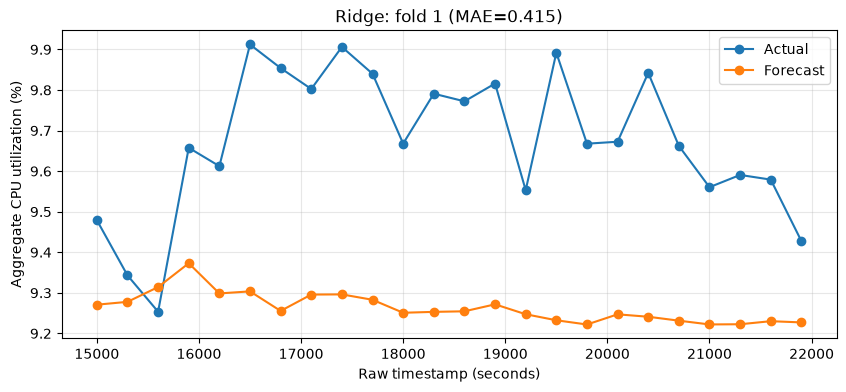

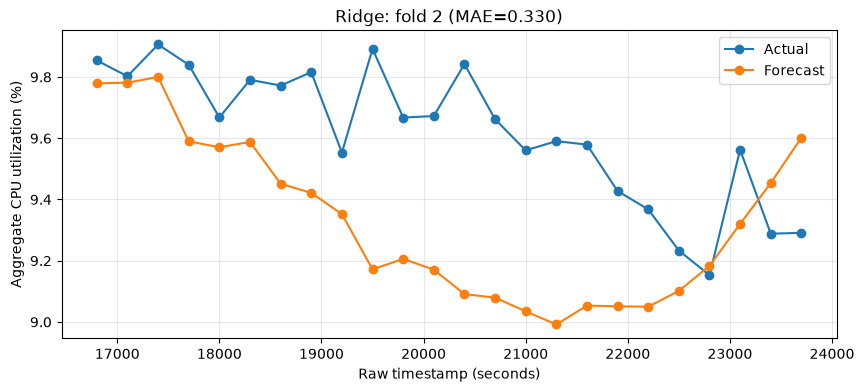

In [4]:
display(analysis.fold_mae)
worst_two_folds = analysis.fold_mae.head(2)["fold"].tolist()
for fold in worst_two_folds:
    fold_data = cv_forecasts.loc[cv_forecasts["fold"] == fold].sort_values("horizon_step")
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(fold_data["timestamp"], fold_data["actual"], marker="o", label="Actual")
    ax.plot(fold_data["timestamp"], fold_data["forecast"], marker="o", label="Forecast")
    ax.set(title=f"{selected_model}: fold {fold} (MAE={analysis.fold_mae.loc[analysis.fold_mae['fold'] == fold, 'mae'].iloc[0]:.3f})",
           xlabel="Raw timestamp (seconds)", ylabel="Aggregate CPU utilization (%)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.show()

**Fold 1 (MAE 0.415):** The forecast remains comparatively flat and below the validation values, likely because the training history does not capture the higher CPU episode that follows.

**Fold 2 (MAE 0.330):** The validation window begins at a high CPU level and then varies; Ridge's recursive forecast smooths the changes, so some transient movement is missed.

## Optional MAE by forecast step

This pools each forecast horizon step across folds; it adds no model or metric beyond the requested MAE.

,horizon_step,mae,observations
0,1,0.121452,7
1,2,0.109221,7
2,3,0.111669,7
3,4,0.190721,7
4,5,0.146511,7
5,6,0.209695,7
6,7,0.288126,7
7,8,0.277658,7
8,9,0.234813,7
9,10,0.322164,7


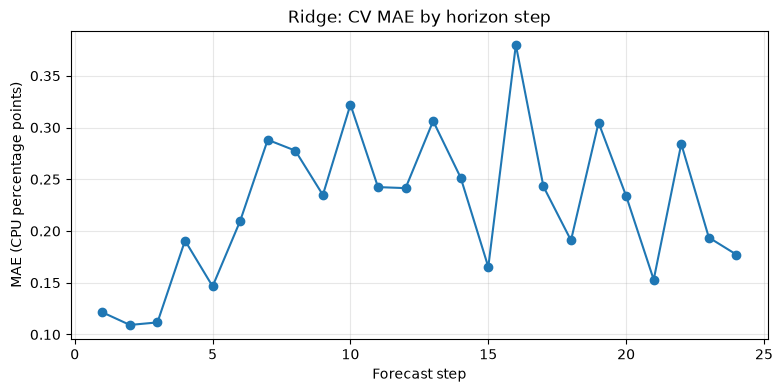

In [5]:
display(analysis.horizon_mae)
ax = analysis.horizon_mae.plot(
    x="horizon_step", y="mae", marker="o", legend=False, figsize=(9, 4),
    title=f"{selected_model}: CV MAE by horizon step",
)
ax.set(xlabel="Forecast step", ylabel="MAE (CPU percentage points)")
ax.grid(True, alpha=0.3)
plt.show()

All forecasts, peak labels, and summaries above use only the 110-point training partition and its rolling-origin folds. The final 24 holdout target values are not used.